In [ ]:
import pandas as pd
import os
from google.colab import drive

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
feat = pd.read_csv("/content/drive/MyDrive/BTT_Amazon1A_Studio/feat.csv")

In [ ]:
feat.head()

,Customer ID,SnapshotMonth,month_orders,month_revenue,month_quantity,month_diff_items,month_last_order,month_cancellations,cancellation_rate,churn,snapshot_end,last_order,first_order,total_orders,tenure_days,recency_days,frequency,orders_30d,orders_60d,orders_90d
0,12346,2009-12,2.0,113.50,26.0,2.0,2009-12-18 10:55:00,0.0,0.000000,0,2009-12-31,2009-12-18 10:55:00,2009-12-14 08:34:00,5.0,16.0,12.0,5.0,5.0,5.0,5.0
1,14606,2009-12,11.0,1401.59,527.0,210.0,2009-12-21 14:33:00,12.0,1.090909,0,2009-12-31,2009-12-21 14:33:00,2009-12-03 12:40:00,8.0,27.0,9.0,8.0,8.0,8.0,8.0
2,14605,2009-12,1.0,208.60,133.0,31.0,2009-12-08 13:59:00,0.0,0.000000,1,2009-12-31,2009-12-08 14:01:00,2009-12-08 13:59:00,2.0,22.0,22.0,2.0,2.0,2.0,2.0
3,14593,2009-12,1.0,391.68,157.0,65.0,2009-12-09 12:57:00,2.0,2.000000,0,2009-12-31,2009-12-09 12:57:00,2009-12-09 12:57:00,1.0,21.0,21.0,1.0,1.0,1.0,1.0
4,14590,2009-12,3.0,349.66,108.0,38.0,2009-12-16 11:26:00,0.0,0.000000,0,2009-12-31,2009-12-16 11:26:00,2009-12-07 14:10:00,3.0,23.0,14.0,3.0,3.0,3.0,3.0


In [ ]:
feat.columns

Index(['Customer ID', 'SnapshotMonth', 'month_orders', 'month_revenue',
       'month_quantity', 'month_diff_items', 'month_last_order',
       'month_cancellations', 'cancellation_rate', 'churn', 'snapshot_end',
       'last_order', 'first_order', 'total_orders', 'tenure_days',
       'recency_days', 'frequency', 'orders_30d', 'orders_60d', 'orders_90d'],
      dtype='object')

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc

FEATURES = ["cancellation_rate","total_orders", "tenure_days",
            "recency_days", "frequency", "orders_30d", "orders_60d",
            "orders_90d", "month_orders", "month_revenue", "month_quantity",
            "month_diff_items", "month_cancellations"]

X = feat[FEATURES]
y = feat['churn']

#train and test splits
X_train,X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Random forest implementation

In [ ]:
#20 decision trees
#create model object and fit to training data
rf_20_model = RandomForestClassifier(criterion='entropy', n_estimators=20, random_state=42)
rf_20_model.fit(X_train, y_train)

#gets the predicted probability that each customer will churn
rf_20_preds = rf_20_model.predict_proba(X_test)
rf_20_predictions = list(rf_20_preds[:, -1])

#80 decision trees
#create model object and fit to training data
rf_80_model = RandomForestClassifier(criterion='entropy', n_estimators=80, random_state=42)
rf_80_model.fit(X_train, y_train)

#gets the predicted probability that each cutomer will churn
rf_80_preds = rf_80_model.predict_proba(X_test)
rf_80_predictions = list(rf_80_preds[:, -1])


In [ ]:
from sklearn.metrics import accuracy_score
#predict class labels for test data
rf_20_pred = rf_20_model.predict(X_test)
rf_80_pred = rf_80_model.predict(X_test)

#calculate accuracy scores
rf_20_acc = accuracy_score(y_test, rf_20_pred)
rf_80_acc = accuracy_score(y_test, rf_80_pred)

#print results
print(f"20 trees accuracy score: {rf_20_acc}")
print(f"80 trees accuracy score: {rf_80_acc}")

20 trees accuracy score: 0.7997159090909091
80 trees accuracy score: 0.8006628787878788


In [ ]:
from sklearn.model_selection import GridSearchCV

#hyperparameter tuning
param_grid = {
    "min_samples_leaf": [1, 5, 10, 50, 100],
    "max_depth": [4, 8, 16, 20, 24],
    "min_samples_split": [2, 5, 10, 20, 50]
}

grid_search = GridSearchCV(
    estimator = RandomForestClassifier(random_state=42, criterion='entropy'),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"hyperparameters: {grid_search.best_params_}")
print(f"best validation f1 score: {grid_search.best_score_:.4f}")

hyperparameters: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 5}
best validation f1 score: 0.4949


In [ ]:
#train model with best hyperparameters
rf_tuned_model = RandomForestClassifier(criterion='entropy', n_estimators=80, random_state=42,
                                     max_depth=20, min_samples_leaf=1, min_samples_split=5)
rf_tuned_model.fit(X_train, y_train)

#gets the predicted probability that each cutomer will churn
rf_tuned_preds = rf_tuned_model.predict_proba(X_test)
rf_tuned_predictions = list(rf_tuned_preds[:, -1])

#predict class labels for test data
rf_tuned_pred = rf_tuned_model.predict(X_test)

#calculate accuracy scores
rf_tuned_acc = accuracy_score(y_test, rf_tuned_pred)


In [ ]:
#print results
print(f"tuned hyperparameter accuracy score: {rf_tuned_acc}")

tuned hyperparameter accuracy score: 0.8011363636363636


# Evaluating Model

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, precision_recall_curve, auc

# Perform imputation first to avoid errors due to NaN values in X_test
median_values = X_train.median()
X_test_clean = X_test.fillna(median_values)

# Re-generate predictions/probabilities with clean test data to prevent any mismatches
y_pred_20 = rf_20_model.predict(X_test_clean)
y_prob_20 = rf_20_model.predict_proba(X_test_clean)[:, 1]

y_pred_80 = rf_80_model.predict(X_test_clean)
y_prob_80 = rf_80_model.predict_proba(X_test_clean)[:, 1]

y_pred_tuned = rf_tuned_model.predict(X_test_clean)
y_prob_tuned = rf_tuned_model.predict_proba(X_test_clean)[:, 1]

models_metrics = {}

for name, y_pred, y_prob in [
    ("20-Tree Model", y_pred_20, y_prob_20),
    ("80-Tree Model", y_pred_80, y_prob_80),
    ("Tuned Model", y_pred_tuned, y_prob_tuned)
]:
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    # PR-AUC
    precision_pts, recall_pts, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(recall_pts, precision_pts)

    models_metrics[name] = {
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    }

metrics_df = pd.DataFrame(models_metrics).T
display(metrics_df)

,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
20-Tree Model,0.549180,0.367728,0.440500,0.806397,0.495819
80-Tree Model,0.549536,0.389682,0.456005,0.798578,0.498508
Tuned Model,0.553488,0.391877,0.458869,0.813756,0.530179


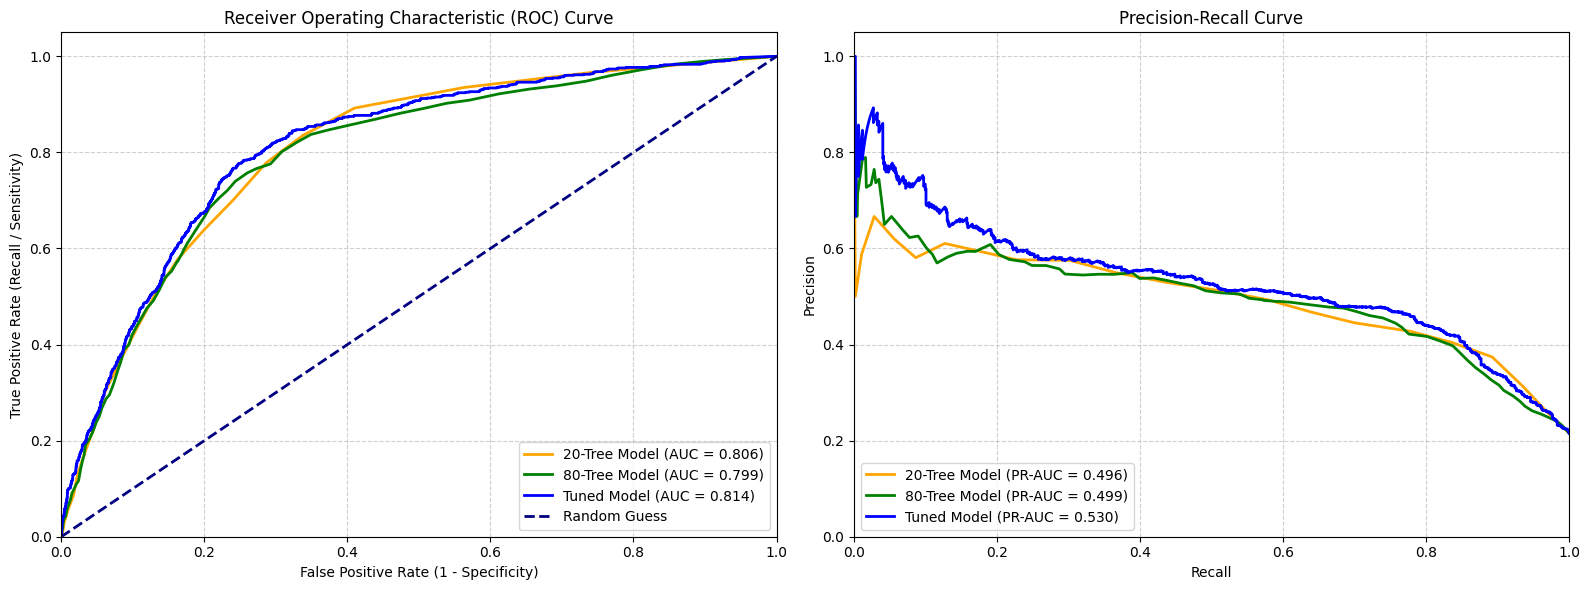

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# Calculate ROC curves and AUC values
fpr_20, tpr_20, _ = roc_curve(y_test, y_prob_20)
roc_auc_20 = auc(fpr_20, tpr_20)

fpr_80, tpr_80, _ = roc_curve(y_test, y_prob_80)
roc_auc_80 = auc(fpr_80, tpr_80)

fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_prob_tuned)
roc_auc_tuned = auc(fpr_tuned, tpr_tuned)

# Calculate Precision-Recall curves and AUC values
prec_20, rec_20, _ = precision_recall_curve(y_test, y_prob_20)
pr_auc_20 = auc(rec_20, prec_20)

prec_80, rec_80, _ = precision_recall_curve(y_test, y_prob_80)
pr_auc_80 = auc(rec_80, prec_80)

prec_tuned, rec_tuned, _ = precision_recall_curve(y_test, y_prob_tuned)
pr_auc_tuned = auc(rec_tuned, prec_tuned)

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Plot ROC Curves
ax1.plot(fpr_20, tpr_20, label=f'20-Tree Model (AUC = {roc_auc_20:.3f})', color='orange', lw=2)
ax1.plot(fpr_80, tpr_80, label=f'80-Tree Model (AUC = {roc_auc_80:.3f})', color='green', lw=2)
ax1.plot(fpr_tuned, tpr_tuned, label=f'Tuned Model (AUC = {roc_auc_tuned:.3f})', color='blue', lw=2)
ax1.plot([0, 1], [0, 1], color='navy', linestyle='--', lw=2, label='Random Guess')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate (1 - Specificity)')
ax1.set_ylabel('True Positive Rate (Recall / Sensitivity)')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve')
ax1.legend(loc="lower right")
ax1.grid(True, linestyle='--', alpha=0.6)

# 2. Plot Precision-Recall Curves
ax2.plot(rec_20, prec_20, label=f'20-Tree Model (PR-AUC = {pr_auc_20:.3f})', color='orange', lw=2)
ax2.plot(rec_80, prec_80, label=f'80-Tree Model (PR-AUC = {pr_auc_80:.3f})', color='green', lw=2)
ax2.plot(rec_tuned, prec_tuned, label=f'Tuned Model (PR-AUC = {pr_auc_tuned:.3f})', color='blue', lw=2)
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve')
ax2.legend(loc="lower left")
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Calculate Precision, Recall, and thresholds specifically for the Tuned Model
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_tuned)

# Avoid division by zero by handling precision + recall = 0
f1_scores = np.zeros_like(thresholds)
for i in range(len(thresholds)):
    if (precisions[i] + recalls[i]) > 0:
        f1_scores[i] = 2 * (precisions[i] * recalls[i]) / (precisions[i] + recalls[i])

# Find the index of the maximum F1 score
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]
best_precision = precisions[best_idx]
best_recall = recalls[best_idx]

print("=== Optimal Threshold Analysis (Tuned Model) ===")
print(f"Optimal Threshold (Max F1-Score): {best_threshold:.4f}")
print(f"Best F1-Score achieved:           {best_f1:.4f}")
print(f"Precision at this threshold:      {best_precision:.4f}")
print(f"Recall at this threshold:         {best_recall:.4f}")

# For comparison with default 0.5 threshold
print("\n--- Compared to Default Threshold (0.5) ---")
print(f"Default F1-Score:                 0.4589")
print(f"Default Precision:                0.5535")
print(f"Default Recall:                   0.3919")

=== Optimal Threshold Analysis (Tuned Model) ===
Optimal Threshold (Max F1-Score): 0.2761
Best F1-Score achieved:           0.5810
Precision at this threshold:      0.4676
Recall at this threshold:         0.7673

--- Compared to Default Threshold (0.5) ---
Default F1-Score:                 0.4589
Default Precision:                0.5535
Default Recall:                   0.3919


=== Top 5 Features Driving Tuned Model Predictions ===


,Feature,Importance
2,tenure_days,0.141716
9,month_revenue,0.135116
11,month_diff_items,0.123037
10,month_quantity,0.121432
1,total_orders,0.093903


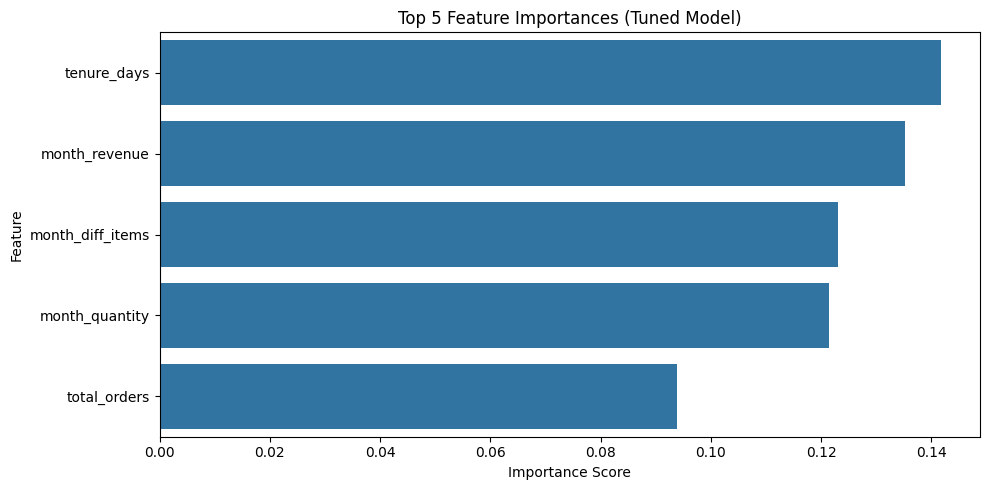

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importances from the tuned model
importances = rf_tuned_model.feature_importances_

# Create a DataFrame for easy sorting and plotting
feature_importance_df = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Get top 5 features
top_5_features = feature_importance_df.head(5)

print("=== Top 5 Features Driving Tuned Model Predictions ===")
display(top_5_features)

# Plot the top 5 feature importances
plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=top_5_features)
plt.title('Top 5 Feature Importances (Tuned Model)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Conclusion

* **Model Optimization**: The Tuned Random Forest Model outperformed the 20-tree and 80-tree baselines, achieving a ROC-AUC of 81.38% and a PR-AUC of 53.02%, showcasing strong discriminative capability between churners and non-churners.

* **Strategic Threshold Shift**: By lowering the decision threshold from the default 0.5 to 0.2761, we dramatically boosted the model's Recall from 39.19% to 76.73%. This calibration ensures that we capture the vast majority of churning customers (minimizing missed opportunities/false negatives) while maintaining a balanced F1-score of 58.10%.

* **Key Business Drivers**: Customer loyalty and engagement are the strongest indicators of churn. Tenure days (14.17%), monthly revenue (13.51%), monthly item diversity (12.30%), and monthly purchase quantity (12.14%) represent the major predictive signals.